In [33]:
!nvidia-smi    # should show a GPU (e.g. Tesla T4). If error: GPU is not enabled.
from google.colab import drive
drive.mount('/content/drive')

Fri Oct 16 16:57:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   77C    P0             33W /   70W |     177MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [34]:
import os, random, time, copy, glob, shutil
import numpy as np, pandas as pd
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import CosineAnnealingLR
from torchvision import transforms, models
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
ROOT = '/content/drive/MyDrive/glaucoma'
RAW  = f'{ROOT}/raw'
DATA = f'{ROOT}/data'
OUT  = f'{ROOT}/results'
os.makedirs(DATA, exist_ok=True); os.makedirs(OUT, exist_ok=True)
IMG, BATCH, EPOCHS, LR, SEED = 224, 32, 15, 1e-4, 123   # SAME for every model (fair comparison)
# SEED is 42 for the first run; later set SEED = 7, then SEED = 123 and re-run the Day 4 cell
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
USE_AMP = (DEVICE == 'cuda')                            # mixed precision = faster training
print('Using device:', DEVICE)
def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

Using device: cuda


In [35]:
IMG_EXT = ('.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp')

rows = []
for ds in sorted(os.listdir(DATA)):
    for cls, label in [('normal', 0), ('glaucoma', 1)]:
        folder = f'{DATA}/{ds}/{cls}'
        if not os.path.isdir(folder): continue
        for f in os.listdir(folder):
            if f.lower().endswith(IMG_EXT):
                rows.append(dict(path=f'{folder}/{f}', label=label, dataset=ds))
df = pd.DataFrame(rows)
df.to_csv(f'{ROOT}/master.csv', index=False)
print(df.groupby(['dataset', 'label']).size().unstack())

label         0    1
dataset             
ACRIMA      309  396
G1020       724  296
ORIGA       482  168
RIM-ONE_DL  313  172


In [36]:
norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])   # ImageNet statistics
train_tf = transforms.Compose([
    transforms.Resize((IMG, IMG)), transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15), transforms.ColorJitter(0.2, 0.2),
    transforms.ToTensor(), norm])
eval_tf = transforms.Compose([transforms.Resize((IMG, IMG)), transforms.ToTensor(), norm])
class FundusDS(Dataset):
    def __init__(self, frame, tf):
        self.paths = frame.path.tolist()
        self.labels = frame.label.values.astype('float32')
        self.tf = tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert('RGB')
        return self.tf(img), torch.tensor(self.labels[i])

In [37]:
def split_source(d, seed):
    trval, te = train_test_split(d, test_size=0.15, stratify=d.label, random_state=seed)
    tr, va = train_test_split(trval, test_size=0.15 / 0.85, stratify=trval.label, random_state=seed)
    return tr, va, te
# quick check
d = df[df.dataset == df.dataset.unique()[0]]
tr, va, te = split_source(d, SEED)
print(len(tr), len(va), len(te), '| glaucoma ratio:',
      tr.label.mean().round(2), va.label.mean().round(2), te.label.mean().round(2))

493 106 106 | glaucoma ratio: 0.56 0.56 0.57


In [38]:
def make_model(name):
    if name == 'resnet50':
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        m.fc = nn.Linear(m.fc.in_features, 1)
    elif name == 'densenet121':
        m = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
        m.classifier = nn.Linear(m.classifier.in_features, 1)
    elif name == 'mobilenet_v2':
        m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, 1)
    elif name == 'efficientnet_b0':
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, 1)
    elif name == 'inception_v3':
        m = models.inception_v3(weights=models.Inception_V3_Weights.IMAGENET1K_V1)
        m.aux_logits = False; m.AuxLogits = None   # turn off the auxiliary head (simplifies training)
        m.fc = nn.Linear(m.fc.in_features, 1)
    else:
        raise ValueError(name)
    return m.to(DEVICE)
print(sum(p.numel() for p in make_model('mobilenet_v2').parameters()) / 1e6, 'million parameters')

2.225153 million parameters


In [39]:
def predict(model, loader):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(DEVICE)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
                out = model(x)
            ps.append(torch.sigmoid(out.float()).squeeze(1).cpu().numpy())
            ys.append(y.numpy())
    return np.concatenate(ys), np.concatenate(ps)
def metrics(y, p, thr):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(auc=roc_auc_score(y, p),
                sens=tp / max(tp + fn, 1), spec=tn / max(tn + fp, 1),
                acc=(tp + tn) / len(y))
def make_loader(frame, tf, shuffle=False, drop_last=False):
    return DataLoader(FundusDS(frame, tf), batch_size=BATCH, shuffle=shuffle,
                      num_workers=2, drop_last=drop_last)

In [40]:
def train_model(name, tr, va, seed, epochs=EPOCHS, patience=5):
    seed_everything(seed)
    model = make_model(name)
    tl = make_loader(tr, train_tf, shuffle=True, drop_last=True)
    vl = make_loader(va, eval_tf)
    pos = float(tr.label.sum()); neg = len(tr) - pos
    crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([neg / pos], device=DEVICE))
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    best_auc, best_state, bad = -1.0, None, 0
    for ep in range(epochs):
        model.train(); tot = 0.0
        for x, y in tl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
                out = model(x).squeeze(1)
            loss = crit(out.float(), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * len(x)
        sched.step()
        yv, pv = predict(model, vl)
        auc = roc_auc_score(yv, pv)
        print(f'  [{name}] epoch {ep+1:02d}  train_loss {tot/len(tr):.3f}  val_auc {auc:.3f}')
        if auc > best_auc:
            best_auc, best_state, bad = auc, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state)
    yv, pv = predict(model, vl)
    fpr, tpr, th = roc_curve(yv, pv)
    thr = float(th[np.argmax(tpr - fpr)])
    return model, thr, float(best_auc)

In [41]:
# ===== R1: re-run Day 4 but SAVE the per-image scores (one file per trained model) =====
# Run after the configuration cell and all function cells (Steps 2.1 to 3.5) and master df (Step 2.4).
# Set SEED = 42, run; then SEED = 7, run; then SEED = 123, run. Your old results_seed*.csv stay untouched.
MODELS  = ['resnet50', 'densenet121', 'mobilenet_v2', 'efficientnet_b0', 'inception_v3']
SOURCES = ['ACRIMA', 'ORIGA', 'RIM-ONE_DL']
TARGETS = SOURCES + ['G1020']
PRED_DIR = f'{OUT}/preds'; os.makedirs(PRED_DIR, exist_ok=True)
for src in SOURCES:
    tr, va, te = split_source(df[df.dataset == src], SEED)      # same split function, same seed
    for name in MODELS:
        f = f'{PRED_DIR}/seed{SEED}_{name}_{src}.csv'
        if os.path.exists(f): continue                          # resume after a Colab disconnect
        t0 = time.time()
        print(f'=== train {name} on {src} (seed {SEED}) ===')
        model, thr, val_auc = train_model(name, tr, va, SEED)
        parts = []
        for tgt in TARGETS:
            d_eval = te if tgt == src else df[df.dataset == tgt]
            y, p = predict(model, make_loader(d_eval, eval_tf))  # order = order of d_eval (no shuffle)
            parts.append(pd.DataFrame(dict(seed=SEED, model=name, source=src, target=tgt,
                                           path=d_eval.path.values, label=y.astype(int),
                                           score=p, thr=thr, val_auc=val_auc)))
        pd.concat(parts, ignore_index=True).to_csv(f, index=False)   # one file per trained network
        del model; torch.cuda.empty_cache()
        print(f'   saved {os.path.basename(f)} in {(time.time()-t0)/60:.1f} min')

=== train resnet50 on ACRIMA (seed 123) ===
  [resnet50] epoch 01  train_loss 0.488  val_auc 0.833
  [resnet50] epoch 02  train_loss 0.228  val_auc 0.994
  [resnet50] epoch 03  train_loss 0.107  val_auc 0.995
  [resnet50] epoch 04  train_loss 0.057  val_auc 0.992
  [resnet50] epoch 05  train_loss 0.049  val_auc 0.996
  [resnet50] epoch 06  train_loss 0.033  val_auc 0.996
  [resnet50] epoch 07  train_loss 0.019  val_auc 1.000
  [resnet50] epoch 08  train_loss 0.034  val_auc 0.997
  [resnet50] epoch 09  train_loss 0.034  val_auc 0.999
  [resnet50] epoch 10  train_loss 0.028  val_auc 0.997
  [resnet50] epoch 11  train_loss 0.018  val_auc 0.996
  [resnet50] epoch 12  train_loss 0.011  val_auc 0.996
   saved seed123_resnet50_ACRIMA.csv in 1.4 min
=== train densenet121 on ACRIMA (seed 123) ===
  [densenet121] epoch 01  train_loss 0.334  val_auc 0.976
  [densenet121] epoch 02  train_loss 0.108  val_auc 0.992
  [densenet121] epoch 03  train_loss 0.053  val_auc 1.000
  [densenet121] epoch 04  t

In [42]:
import os, pandas as pd

SEED_CHECK = 123
MODELS  = ['resnet50', 'densenet121', 'mobilenet_v2', 'efficientnet_b0', 'inception_v3']
SOURCES = ['ACRIMA', 'ORIGA', 'RIM-ONE_DL']
TARGETS = SOURCES + ['G1020']
PRED_DIR = f'{OUT}/preds'

problems = []
for src in SOURCES:
    for m in MODELS:
        f = f'{PRED_DIR}/seed{SEED_CHECK}_{m}_{src}.csv'
        if not os.path.isfile(f):
            problems.append(f'MISSING file: {os.path.basename(f)}'); continue
        try:
            d = pd.read_csv(f)
        except Exception as e:
            problems.append(f'UNREADABLE: {os.path.basename(f)} ({e})'); continue
        if set(d.target) != set(TARGETS):
            problems.append(f'{os.path.basename(f)}: targets = {sorted(set(d.target))}')
        if d.score.isna().any():
            problems.append(f'{os.path.basename(f)}: NaN scores')
        if d.thr.nunique() != 1:
            problems.append(f'{os.path.basename(f)}: more than one threshold')
        if (d.seed != SEED_CHECK).any():
            problems.append(f'{os.path.basename(f)}: wrong seed inside file')
        for t, g in d.groupby('target'):
            if g.label.nunique() < 2:
                problems.append(f'{os.path.basename(f)}: target {t} has only one class')

n_files = len([x for x in os.listdir(PRED_DIR) if x.startswith(f'seed{SEED_CHECK}_')])
print('files for seed', SEED_CHECK, ':', n_files, '(expected 15)')
if problems:
    print('PROBLEMS FOUND:'); [print(' -', p) for p in problems]
else:
    print('ALL OK: seed', SEED_CHECK, 'finished correctly')

files for seed 123 : 15 (expected 15)
ALL OK: seed 123 finished correctly


In [43]:
# ===== R2: baseline check - do the saved scores reproduce your paper numbers? (seed 42 shown) =====
# Uses metrics() from Step 3.4. Run once per seed (change 42 to 7 and 123).
S = 7
old = pd.read_csv(f'{OUT}/results_seed{S}.csv')
rows = []
for fn in sorted(os.listdir(PRED_DIR)):
    if not fn.startswith(f'seed{S}_'): continue
    p = pd.read_csv(f'{PRED_DIR}/{fn}')
    for tgt, g in p.groupby('target'):
        m = metrics(g.label.values, g.score.values, g.thr.iloc[0])
        rows.append(dict(model=g.model.iloc[0], source=g.source.iloc[0], target=tgt,
                         auc_new=m['auc'], spec_new=m['spec'], sens_new=m['sens']))
cmp_ = pd.DataFrame(rows).merge(old[['model', 'source', 'target', 'auc', 'spec', 'sens']],
                                on=['model', 'source', 'target'], validate='one_to_one')
print('rows compared:', len(cmp_), '(expected 60)')
print('max  |AUC  new - old|:', round((cmp_.auc_new  - cmp_.auc ).abs().max(),  3))
print('max  |spec new - old|:', round((cmp_.spec_new - cmp_.spec).abs().max(),  3))
print('mean |spec new - old|:', round((cmp_.spec_new - cmp_.spec).abs().mean(), 3))

rows compared: 60 (expected 60)
max  |AUC  new - old|: 0.116
max  |spec new - old|: 0.459
mean |spec new - old|: 0.072


In [44]:
import os, shutil
import pandas as pd

PRED_DIR = f'{OUT}/preds'
OLD = f'{OUT}/old_run'; os.makedirs(OLD, exist_ok=True)   # backup of the old results
MODELS  = ['resnet50', 'densenet121', 'mobilenet_v2', 'efficientnet_b0', 'inception_v3']
SOURCES = ['ACRIMA', 'ORIGA', 'RIM-ONE_DL']
TARGETS = SOURCES + ['G1020']

for S in [42, 7, 123]:
    rows = []
    for src in SOURCES:
        for m in MODELS:
            f = f'{PRED_DIR}/seed{S}_{m}_{src}.csv'
            assert os.path.isfile(f), f'missing {f}'
            d = pd.read_csv(f)
            for tgt in TARGETS:
                g = d[d.target == tgt]
                mt = metrics(g.label.values, g.score.values, g.thr.iloc[0])
                rows.append(dict(seed=S, model=m, source=src, target=tgt,
                                 setting='in-domain' if tgt == src else 'cross-domain',
                                 n=len(g), val_auc=g.val_auc.iloc[0], thr=g.thr.iloc[0], **mt))
    out = f'{OUT}/results_seed{S}.csv'
    if os.path.exists(out): shutil.move(out, f'{OLD}/results_seed{S}.csv')   # keep old file safe
    pd.DataFrame(rows).to_csv(out, index=False)
    print('seed', S, 'rows:', len(rows), '(expected 60)')

seed 42 rows: 60 (expected 60)
seed 7 rows: 60 (expected 60)
seed 123 rows: 60 (expected 60)


files loaded: {42: 60, 7: 60, 123: 60} rows per seed
primary rows 135 | external rows 45 | ignored rows with G1020 as SOURCE 0 (should be 0; G1020 is test-only)
completeness OK: 3 seeds x 5 models x (9 primary + 3 G1020) results present
saved primary_3x3_auc_mean_sd.csv (45, 8)
saved primary_sens_spec_mean_sd.csv (45, 17)

PRIMARY train/test performance (3 seeds)
          Model     Source     Target      Setting AUC Mean ± SD Sensitivity Mean ± SD Specificity Mean ± SD Accuracy Mean ± SD
       ResNet50     ACRIMA     ACRIMA    in-domain 1.000 ± 0.000         0.983 ± 0.017         0.978 ± 0.038      0.981 ± 0.009
       ResNet50     ACRIMA      ORIGA cross-source 0.695 ± 0.009         0.663 ± 0.122         0.635 ± 0.107      0.642 ± 0.049
       ResNet50     ACRIMA RIM-ONE DL cross-source 0.606 ± 0.010         0.891 ± 0.064         0.247 ± 0.076      0.476 ± 0.026
       ResNet50      ORIGA     ACRIMA cross-source 0.734 ± 0.050         0.707 ± 0.115         0.585 ± 0.275      0.653 ± 

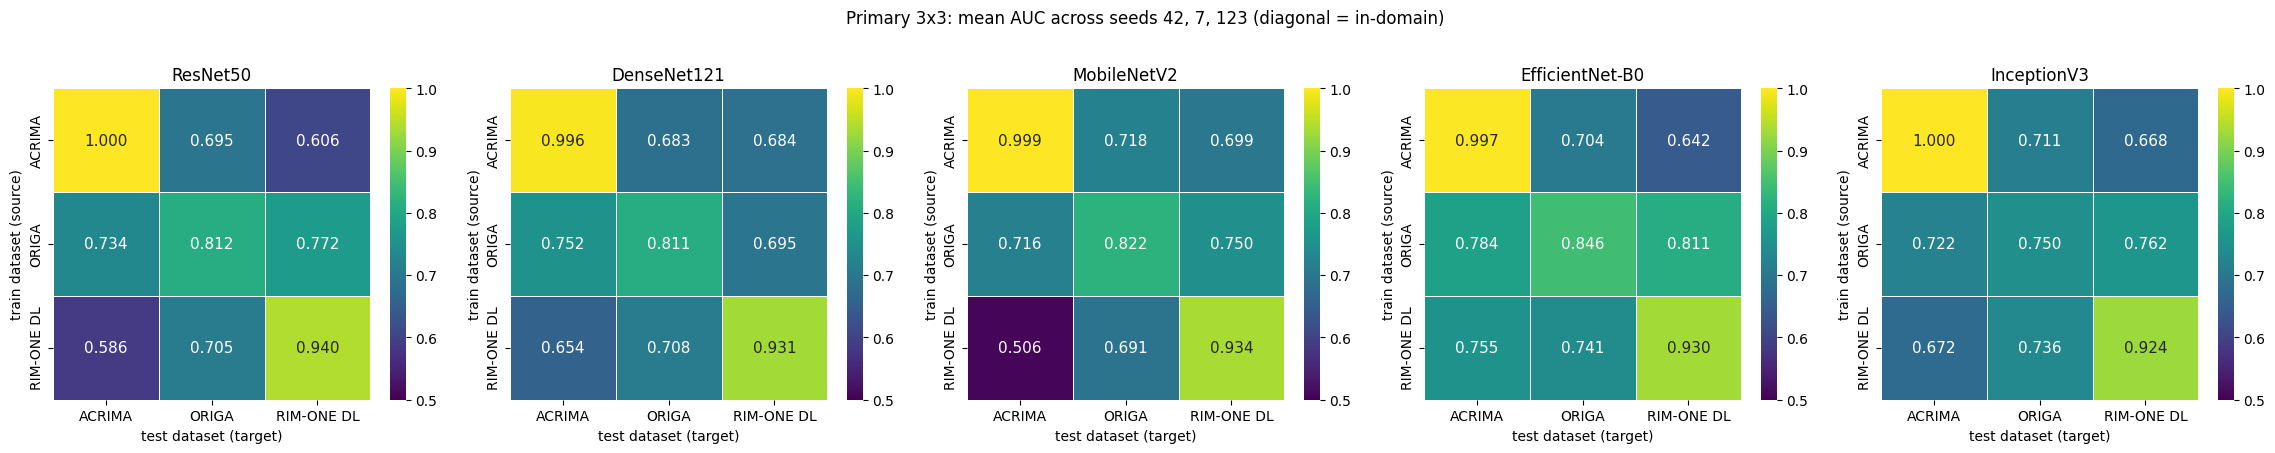

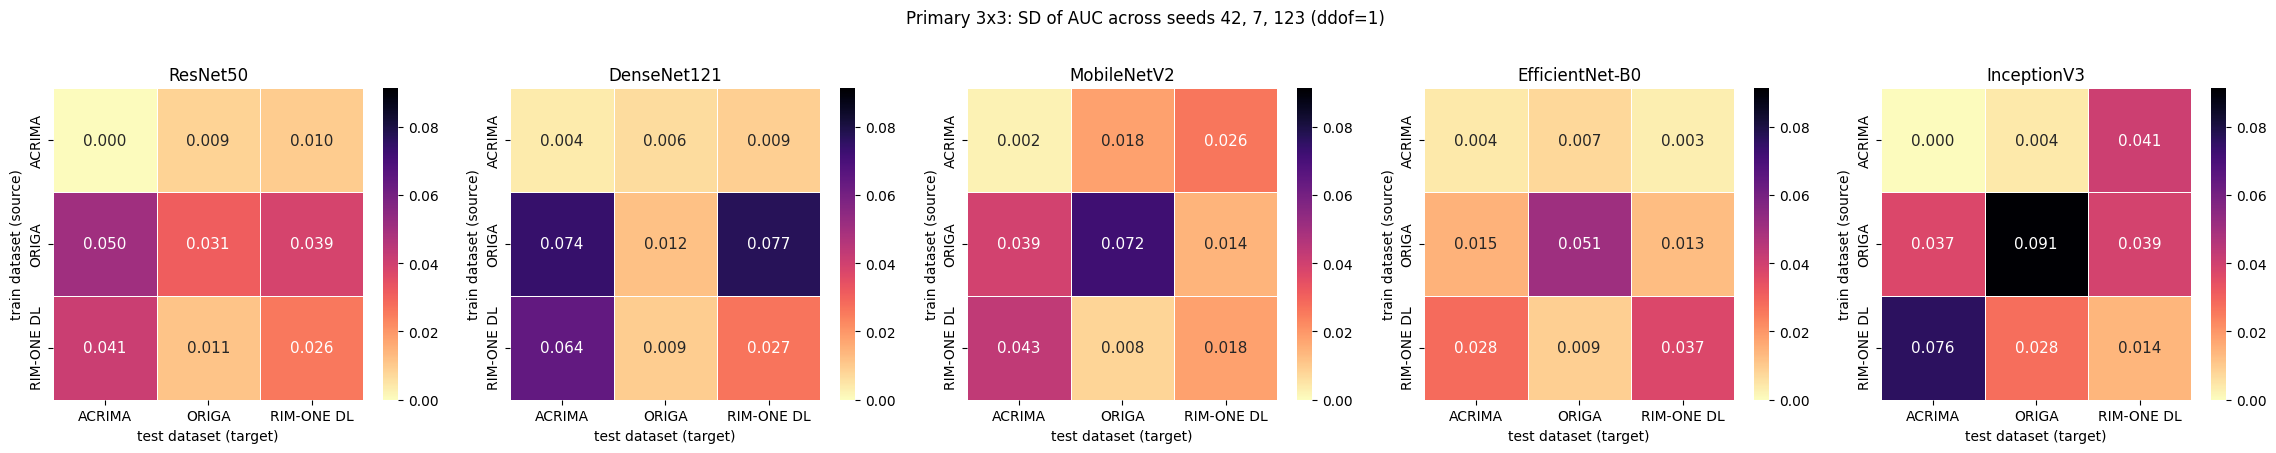

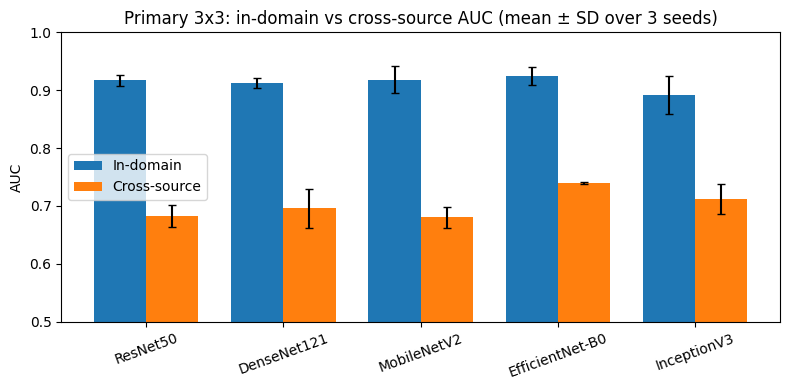

In [45]:
# ===== Step 5 : results, reporting and statistical analysis =====
# Reads ONLY the three seed files. Trains nothing.
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from itertools import product
# ---- 5.0  Fixed definitions  -------------------
EXPECTED_SEEDS = [42, 7, 123]
SEED_FILES = {s: f'{OUT}/results_seed{s}.csv' for s in EXPECTED_SEEDS}   # no glob
REQ_COLS = ['seed', 'model', 'source', 'target', 'setting', 'n', 'val_auc', 'thr',
            'auc', 'sens', 'spec', 'acc']
MODELS   = ['resnet50', 'densenet121', 'mobilenet_v2', 'efficientnet_b0', 'inception_v3']
PRIMARY  = ['ACRIMA', 'ORIGA', 'RIM-ONE_DL']      # folder names used in data/
EXTERNAL = 'G1020'                                # test-only external dataset
METRICS  = ['auc', 'sens', 'spec', 'acc']
LABEL = {'ACRIMA': 'ACRIMA', 'ORIGA': 'ORIGA', 'RIM-ONE_DL': 'RIM-ONE DL', 'G1020': 'G1020',
         'resnet50': 'ResNet50', 'densenet121': 'DenseNet121', 'mobilenet_v2': 'MobileNetV2',
         'efficientnet_b0': 'EfficientNet-B0', 'inception_v3': 'InceptionV3'}
RANK = {k: i for i, k in enumerate(MODELS + PRIMARY + [EXTERNAL] + ['in-domain', 'cross-source'])}
def check(cond, msg):
    if not cond: raise ValueError('REPORTING CHECK FAILED: ' + msg)
def pm(m, s, d=3):                         # "0.912 ± 0.021"
    return f'{m:.{d}f} ± {s:.{d}f}'
def sort_rows(df):
    cols = [c for c in ['model', 'source', 'target', 'setting'] if c in df.columns]
    return df.sort_values(cols, key=lambda s: s.map(RANK)).reset_index(drop=True)
def save(df, name):
    df.to_csv(f'{OUT}/{name}', index=False, encoding='utf-8-sig')
    print('saved', name, df.shape)
def summarize(df, keys, cols=METRICS):
    """mean and sample SD (ddof=1) ACROSS SEEDS. Every group must hold exactly one row per seed,
    so no image-level or repeated-row averaging can happen."""
    g = df.groupby(keys, sort=False)
    out = g[cols].mean().add_suffix('_mean').join(g[cols].std(ddof=1).add_suffix('_sd'))
    out['n_seeds'] = g['seed'].nunique()
    check((out.n_seeds == len(EXPECTED_SEEDS)).all(), f'{keys}: a group does not have all 3 seeds')
    check((g.size() == out.n_seeds).all(), f'{keys}: more than one row per seed in a group')
    for c in cols:
        out[f'{c}_mean_sd'] = [pm(m, s) for m, s in zip(out[f'{c}_mean'], out[f'{c}_sd'])]
    return out.reset_index()
# ---- 5.1  Load ONLY the three expected files and validate them ----------------------
frames = []
for s, f in SEED_FILES.items():
    if not os.path.isfile(f): raise FileNotFoundError(f'Missing results file for seed {s}: {f}')
    try: d = pd.read_csv(f)
    except Exception as e: raise RuntimeError(f'Cannot read {f}: {e}')
    absent = [c for c in REQ_COLS if c not in d.columns]
    check(not absent, f'{f}: missing columns {absent}')
    check(len(d) > 0, f'{f} is empty')
    found = sorted(d['seed'].unique().tolist())
    check(found == [s], f'{f}: expected seed [{s}] but file contains {found}')
    frames.append(d[REQ_COLS].copy())
allr = pd.concat(frames, ignore_index=True)
for c in ['model', 'source', 'target', 'setting']:
    allr[c] = allr[c].astype(str).str.strip()
check(sorted(allr.seed.unique().tolist()) == sorted(EXPECTED_SEEDS), 'seed set is not {42, 7, 123}')
check(set(allr.model) <= set(MODELS), f'unknown models: {set(allr.model) - set(MODELS)}')
check((set(allr.source) | set(allr.target)) <= set(PRIMARY + [EXTERNAL]),
      f'unknown datasets: {(set(allr.source) | set(allr.target)) - set(PRIMARY + [EXTERNAL])}')
dups = allr[allr.duplicated(['seed', 'model', 'source', 'target'], keep=False)]
check(len(dups) == 0, f'duplicate (seed, model, source, target) rows:\n{dups}')
exp_set = np.where(allr.source == allr.target, 'in-domain', 'cross-domain')
check((allr.setting.values == exp_set).all(), "'setting' disagrees with source == target")
print('files loaded:', {s: int((allr.seed == s).sum()) for s in EXPECTED_SEEDS}, 'rows per seed')
# ---- 5.2  Scope split: PRIMARY 3x3 vs EXTERNAL G1020 (they can never mix) -----------
prim = allr[allr.source.isin(PRIMARY) & allr.target.isin(PRIMARY)].copy()
ext  = allr[allr.source.isin(PRIMARY) & (allr.target == EXTERNAL)].copy()
rest = allr.drop(index=prim.index.union(ext.index))
check(rest.source.eq(EXTERNAL).all(), 'unexpected rows outside primary/external scope')
check(~prim.source.eq(EXTERNAL).any() and ~prim.target.eq(EXTERNAL).any(), 'G1020 leaked into primary')
check(ext.target.eq(EXTERNAL).all() and ext.source.isin(PRIMARY).all(), 'external table is malformed')
print(f'primary rows {len(prim)} | external rows {len(ext)} | '
      f'ignored rows with G1020 as SOURCE {len(rest)} (should be 0; G1020 is test-only)')
# ---- 5.3  Missing-result detection (never silently ignored) -------------------------
expected = pd.DataFrame(list(product(EXPECTED_SEEDS, MODELS, PRIMARY, PRIMARY + [EXTERNAL])),
                        columns=['seed', 'model', 'source', 'target'])
chk = expected.merge(allr[['seed', 'model', 'source', 'target']], how='left', indicator=True)
missing = chk[chk['_merge'] == 'left_only'].drop(columns='_merge')
if len(missing):
    missing['setting'] = np.where(missing.source == missing.target, 'in-domain', 'cross-domain')
    print(missing[['model', 'source', 'target', 'setting', 'seed']].to_string(index=False))
    raise ValueError(f'{len(missing)} required result(s) missing (listed above): '
                     'finish those runs before reporting.')
for d_ in (prim, ext):
    d_[METRICS] = d_[METRICS].apply(pd.to_numeric, errors='raise').astype(float)
    check(d_[METRICS].notna().all().all(), 'NaN found in auc/sens/spec/acc')
check(len(prim) == 3 * 5 * 9 and len(ext) == 3 * 5 * 3, 'unexpected number of result rows')
print('completeness OK: 3 seeds x 5 models x (9 primary + 3 G1020) results present')
# ---- 5.4  PRIMARY 3x3: per-cell mean and SD across seeds ----------------------------
cell = sort_rows(summarize(prim, ['model', 'source', 'target']))
cell.insert(3, 'setting', np.where(cell.source == cell.target, 'in-domain', 'cross-source'))
save(cell[['model', 'source', 'target', 'setting', 'n_seeds',
           'auc_mean', 'auc_sd', 'auc_mean_sd']], 'primary_3x3_auc_mean_sd.csv')
save(cell[['model', 'source', 'target', 'setting', 'n_seeds'] +
          [f'{m}_{k}' for m in METRICS for k in ('mean', 'sd', 'mean_sd')]],
     'primary_sens_spec_mean_sd.csv')
# per-cell AUC, sens, spec, acc
# detailed train/test table (display version)
detail = cell[['model', 'source', 'target', 'setting', 'auc_mean_sd',
               'sens_mean_sd', 'spec_mean_sd', 'acc_mean_sd']].copy()
for c in ['model', 'source', 'target']: detail[c] = detail[c].map(LABEL)
detail.columns = ['Model', 'Source', 'Target', 'Setting', 'AUC Mean ± SD',
                  'Sensitivity Mean ± SD', 'Specificity Mean ± SD', 'Accuracy Mean ± SD']
print('\nPRIMARY train/test performance (3 seeds)'); print(detail.to_string(index=False))
# ---- 5.5  PRIMARY AUC DROP: seed-level FIRST, aggregate afterwards ------------------
lvl = prim.groupby(['model', 'seed', 'setting'], as_index=False)[METRICS].mean()
cnt = prim.groupby(['model', 'seed', 'setting']).size().unstack('setting')
check((cnt['in-domain'] == 3).all() and (cnt['cross-domain'] == 6).all(),
      'need 3 diagonal and 6 off-diagonal cells per model and seed')
wide = lvl.pivot(index=['model', 'seed'], columns='setting', values='auc').reset_index()
wide = wide.rename(columns={'in-domain': 'in_domain_auc', 'cross-domain': 'cross_source_auc'})
wide['auc_drop'] = wide.in_domain_auc - wide.cross_source_auc           # per seed
wide = wide.sort_values(['model', 'seed'], key=lambda s: s.map(RANK) if s.name == 'model' else s)
save(wide, 'primary_auc_drop_per_seed.csv')                              # audit trail
summ = sort_rows(summarize(wide, ['model'], cols=['in_domain_auc', 'cross_source_auc', 'auc_drop']))
save(summ, 'primary_model_summary_mean_sd.csv')
tab = pd.DataFrame({'Model': summ.model.map(LABEL), 'In-domain AUC': summ.in_domain_auc_mean_sd,
                    'Cross-source AUC': summ.cross_source_auc_mean_sd, 'AUC Drop': summ.auc_drop_mean_sd})
print('\nPRIMARY model summary (mean ± SD over 3 seeds)'); print(tab.to_string(index=False))
# ---- 5.6  Sensitivity / specificity / accuracy by model (seed-level, then across seeds)
lvl2 = lvl.copy(); lvl2['setting'] = lvl2.setting.replace({'cross-domain': 'cross-source'})
ssa = sort_rows(summarize(lvl2, ['model', 'setting']))
save(ssa[['model', 'setting', 'n_seeds'] + [f'{m}_{k}' for m in METRICS for k in ('mean', 'sd', 'mean_sd')]],
     'primary_sens_spec_by_model_mean_sd.csv')
t2 = ssa[['model', 'setting', 'sens_mean_sd', 'spec_mean_sd', 'acc_mean_sd']].copy()
t2['model'] = t2.model.map(LABEL)
t2.columns = ['Model', 'Setting', 'Sensitivity', 'Specificity', 'Accuracy']
print('\nSensitivity / specificity / accuracy at the stored validation threshold'); print(t2.to_string(index=False))
# ---- 5.7  EXTERNAL G1020 (separate from everything above) ---------------------------
ext_tab = sort_rows(summarize(ext, ['model', 'source', 'target']))
save(ext_tab[['model', 'source', 'target', 'n_seeds'] +
             [f'{m}_{k}' for m in METRICS for k in ('mean', 'sd', 'mean_sd')]], 'external_G1020_mean_sd.csv')
ind = prim[prim.setting == 'in-domain'][['seed', 'model', 'source', 'auc']].rename(columns={'auc': 'in_domain_auc'})
g10 = ext[['seed', 'model', 'source', 'auc']].rename(columns={'auc': 'g1020_auc'})
ed = ind.merge(g10, on=['seed', 'model', 'source'], how='inner', validate='one_to_one')
check(len(ed) == len(ext), 'in-domain / G1020 rows could not be paired one-to-one')
ed['external_drop'] = ed.in_domain_auc - ed.g1020_auc                    # per seed
save(sort_rows(ed), 'external_G1020_drop_per_seed.csv')
ed_tab = sort_rows(summarize(ed, ['model', 'source'], cols=['in_domain_auc', 'g1020_auc', 'external_drop']))
save(ed_tab, 'external_G1020_drop_mean_sd.csv')
g_tab = pd.DataFrame({'Model': ed_tab.model.map(LABEL), 'Train Source': ed_tab.source.map(LABEL),
                      'G1020 AUC': ed_tab.g1020_auc_mean_sd, 'External Drop': ed_tab.external_drop_mean_sd})
print('\nEXTERNAL G1020 (mean ± SD over 3 seeds)'); print(g_tab.to_string(index=False))
# ---- 5.8  Heatmaps (primary 3x3 only) ----------------------------------------------
def draw_heatmaps(stat, fname, title, cmap, vmin, vmax, fmt):
    fig, axes = plt.subplots(1, len(MODELS), figsize=(4.6 * len(MODELS), 4.4))
    for ax, m in zip(axes, MODELS):
        mat = (cell[cell.model == m].pivot(index='source', columns='target', values=stat)
               .reindex(index=PRIMARY, columns=PRIMARY).rename(index=LABEL, columns=LABEL))
        sns.heatmap(mat, annot=True, fmt=fmt, vmin=vmin, vmax=vmax, cmap=cmap, linewidths=0.5,
                    cbar=True, ax=ax, annot_kws={'size': 11})
        ax.set_title(LABEL[m]); ax.set_xlabel('test dataset (target)'); ax.set_ylabel('train dataset (source)')
    fig.suptitle(title, y=1.02); plt.tight_layout()
    plt.savefig(f'{OUT}/{fname}', dpi=200, bbox_inches='tight'); plt.show()
draw_heatmaps('auc_mean', 'primary_auc_mean_heatmaps.png',
              'Primary 3x3: mean AUC across seeds 42, 7, 123 (diagonal = in-domain)',
              'viridis', 0.5, 1.0, '.3f')
draw_heatmaps('auc_sd', 'primary_auc_sd_heatmaps.png',
              'Primary 3x3: SD of AUC across seeds 42, 7, 123 (ddof=1)',
              'magma_r', 0.0, max(0.05, float(cell.auc_sd.max())), '.3f')
# ---- 5.9  Optional bar chart (replaces old Step 5.3) -------------------------------
x = np.arange(len(summ)); w = 0.38
plt.figure(figsize=(8, 4))
plt.bar(x - w / 2, summ.in_domain_auc_mean, w, yerr=summ.in_domain_auc_sd, capsize=3, label='In-domain')
plt.bar(x + w / 2, summ.cross_source_auc_mean, w, yerr=summ.cross_source_auc_sd, capsize=3, label='Cross-source')
plt.xticks(x, [LABEL[m] for m in summ.model], rotation=20); plt.ylim(0.5, 1.0); plt.ylabel('AUC')
plt.title('Primary 3x3: in-domain vs cross-source AUC (mean ± SD over 3 seeds)')
plt.legend(); plt.tight_layout(); plt.savefig(f'{OUT}/primary_in_vs_cross.png', dpi=200); plt.show()

prediction rows: 105255 | files: 45 (expected 45)
saved recal_pair_seed.csv (135, 23)
saved recal_primary_model_mean_sd.csv (6, 26)
saved recal_primary_pair_mean_sd.csv (30, 28)
saved recal_primary_source_target_mean_sd.csv (6, 27)

PRIMARY cross-source, calibration = 10% of target (mean ± SD over 3 seeds)
          Model Specificity before Specificity after Sensitivity before Sensitivity after Balanced acc. before Balanced acc. after
       ResNet50      0.458 ± 0.076     0.634 ± 0.024      0.780 ± 0.054     0.619 ± 0.029        0.619 ± 0.013       0.626 ± 0.013
    DenseNet121      0.489 ± 0.036     0.673 ± 0.030      0.723 ± 0.026     0.589 ± 0.020        0.606 ± 0.027       0.631 ± 0.025
    MobileNetV2      0.463 ± 0.104     0.658 ± 0.029      0.728 ± 0.078     0.597 ± 0.014        0.595 ± 0.021       0.627 ± 0.012
EfficientNet-B0      0.490 ± 0.170     0.701 ± 0.008      0.774 ± 0.097     0.629 ± 0.001        0.632 ± 0.038       0.665 ± 0.004
    InceptionV3      0.630 ± 0.119   

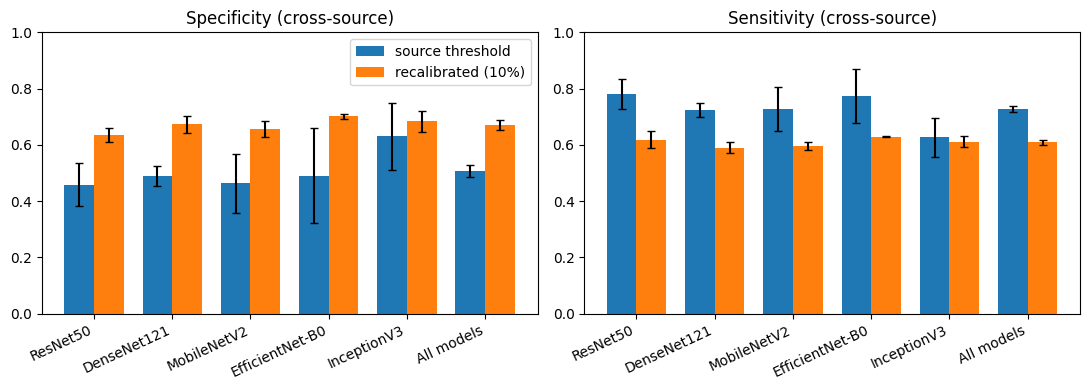

saved recal_sweep_cal_fraction.csv (4, 25)
   cal_frac  spec_before_mean  spec_after_mean  sens_after_mean  \
0      0.05             0.506            0.680            0.587   
1      0.10             0.506            0.669            0.610   
2      0.20             0.506            0.664            0.623   
3      0.30             0.506            0.665            0.625   

   bal_after_mean  
0           0.634  
1           0.639  
2           0.644  
3           0.645  


In [46]:
# ===== R3: threshold recalibration analysis =====
CAL_FRAC = 0.10        # share of the TARGET dataset used as calibration set
N_REP    = 200         # random calibration/evaluation splits per (seed, model, source, target)
SEEDS    = [42, 7, 123]
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.model_selection import train_test_split
MODELS   = ['resnet50', 'densenet121', 'mobilenet_v2', 'efficientnet_b0', 'inception_v3']
PRIMARY  = ['ACRIMA', 'ORIGA', 'RIM-ONE_DL']
EXTERNAL = 'G1020'
PRED_DIR = f'{OUT}/preds'
LABEL = {'ACRIMA': 'ACRIMA', 'ORIGA': 'ORIGA', 'RIM-ONE_DL': 'RIM-ONE DL', 'G1020': 'G1020',
         'resnet50': 'ResNet50', 'densenet121': 'DenseNet121', 'mobilenet_v2': 'MobileNetV2',
         'efficientnet_b0': 'EfficientNet-B0', 'inception_v3': 'InceptionV3', 'ALL': 'All models'}
VAL = ['sens_before', 'sens_after', 'spec_before', 'spec_after', 'acc_before', 'acc_after',
       'bal_before', 'bal_after', 'd_sens', 'd_spec', 'd_acc', 'd_bal']
def check(cond, msg):
    if not cond: raise ValueError('RECAL CHECK FAILED: ' + msg)
def pm(m, s, d=3): return f'{m:.{d}f} ± {s:.{d}f}'
def save(d, name): d.to_csv(f'{OUT}/{name}', index=False, encoding='utf-8-sig'); print('saved', name, d.shape)
def youden_thr(y, p):
    fpr, tpr, th = roc_curve(y, p)
    k = 1 + int(np.argmax((tpr - fpr)[1:]))       # skip the first (infinite) threshold
    return float(th[k])
def rates(y, p, thr):
    pred = p >= thr; pos = (y == 1); neg = (y == 0)
    return ((pred & pos).sum() / pos.sum(),        # sensitivity
            (~pred & neg).sum() / neg.sum(),       # specificity
            (pred == pos).mean())                  # accuracy
# ---- load and validate all prediction files ------------------------------------------
parts = []
for s in SEEDS:
    for m in MODELS:
        for src in PRIMARY:
            f = f'{PRED_DIR}/seed{s}_{m}_{src}.csv'
            if not os.path.isfile(f): raise FileNotFoundError(f'missing {f} (run R1 for seed {s})')
            d = pd.read_csv(f)
            check(d.seed.nunique() == 1 and d.seed.iloc[0] == s, f'{f}: wrong seed')
            check(set(d.target) == set(PRIMARY + [EXTERNAL]), f'{f}: targets {set(d.target)}')
            check(d.thr.nunique() == 1, f'{f}: more than one threshold')
            parts.append(d)
P = pd.concat(parts, ignore_index=True)
print('prediction rows:', len(P), '| files:', len(parts), '(expected 45)')
# ---- core: recalibrate on a small part of the target, evaluate on the rest ------------
def recal_pairs(P, frac, n_rep):
    out = []
    for (s, m, src, tgt), g in P.groupby(['seed', 'model', 'source', 'target'], sort=False):
        if tgt == src: continue                    # in-domain is not recalibrated
        y = g.label.values.astype(int); p = g.score.values; thr_src = float(g.thr.iloc[0])
        idx = np.arange(len(y)); R = []
        for r in range(n_rep):
            ci, ei = train_test_split(idx, train_size=frac, stratify=y, random_state=1000 * s + r)
            thr_c = youden_thr(y[ci], p[ci])                 # step 3: cutoff from calibration part only
            b = rates(y[ei], p[ei], thr_src)                 # BEFORE: source threshold on the 90 %
            a = rates(y[ei], p[ei], thr_c)                   # AFTER : new threshold on the SAME 90 %
            R.append([thr_c, *b, *a])
        R = np.array(R)
        out.append(dict(seed=s, model=m, source=src, target=tgt, n_cal=len(ci),
                        n_cal_pos=int(y[ci].sum()), n_eval=len(ei), auc_target=roc_auc_score(y, p),
                        thr_src=thr_src, thr_cal=R[:, 0].mean(), thr_cal_sd_over_splits=R[:, 0].std(ddof=1),
                        sens_before=R[:, 1].mean(), spec_before=R[:, 2].mean(), acc_before=R[:, 3].mean(),
                        sens_after=R[:, 4].mean(), spec_after=R[:, 5].mean(), acc_after=R[:, 6].mean()))
    o = pd.DataFrame(out)
    o['bal_before'] = (o.sens_before + o.spec_before) / 2
    o['bal_after'] = (o.sens_after + o.spec_after) / 2
    for c in ['sens', 'spec', 'acc', 'bal']: o[f'd_{c}'] = o[f'{c}_after'] - o[f'{c}_before']
    return o
rec = recal_pairs(P, CAL_FRAC, N_REP)
save(rec, 'recal_pair_seed.csv')                      # audit trail: one row per seed/model/pair
prim = rec[rec.target.isin(PRIMARY)].copy()          # 6 cross-source pairs per model and seed
ext  = rec[rec.target == EXTERNAL].copy()            # G1020: reported separately, never pooled
check(len(prim) == 3 * 5 * 6 and len(ext) == 3 * 5 * 3, 'unexpected number of pair rows')
def mean_sd(d, keys, cols=VAL):
    g = d.groupby(keys, sort=False)
    out = g[cols].mean().add_suffix('_mean').join(g[cols].std(ddof=1).add_suffix('_sd'))
    out['n_seeds'] = g['seed'].nunique()
    check((out.n_seeds == len(SEEDS)).all(), f'{keys}: a group lacks a seed')
    return out.reset_index()
def ci95(x):
    x = np.asarray(x, float); h = stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return x.mean() - h, x.mean() + h
def model_level(d):                 # seed level FIRST (mean over pairs), then mean ± SD over seeds
    sm = d.groupby(['model', 'seed'], as_index=False, sort=False)[VAL].mean()
    al = sm.groupby('seed', as_index=False, sort=False)[VAL].mean(); al.insert(0, 'model', 'ALL')
    return mean_sd(sm, ['model']), mean_sd(al, ['model']), al
mt, at, al_seed = model_level(prim)
tab = pd.concat([mt, at], ignore_index=True)
save(tab, 'recal_primary_model_mean_sd.csv')
save(mean_sd(prim, ['model', 'source', 'target']), 'recal_primary_pair_mean_sd.csv')
sp = prim.groupby(['source', 'target', 'seed'], as_index=False)[VAL].mean()   # mean over models, per seed
save(mean_sd(sp, ['source', 'target']), 'recal_primary_source_target_mean_sd.csv')
show = pd.DataFrame({'Model': tab.model.map(LABEL)})
for c, nm in [('spec', 'Specificity'), ('sens', 'Sensitivity'), ('bal', 'Balanced acc.')]:
    show[f'{nm} before'] = [pm(a, b) for a, b in zip(tab[f'{c}_before_mean'], tab[f'{c}_before_sd'])]
    show[f'{nm} after'] = [pm(a, b) for a, b in zip(tab[f'{c}_after_mean'], tab[f'{c}_after_sd'])]
print(f'\nPRIMARY cross-source, calibration = {CAL_FRAC:.0%} of target (mean ± SD over 3 seeds)')
print(show.to_string(index=False))
for c in ['d_spec', 'd_sens', 'd_bal']:
    lo, hi = ci95(al_seed[c])
    print(f'All models, change in {c[2:]}: {al_seed[c].mean():+.3f} (95% CI {lo:+.3f} to {hi:+.3f})')
# ---- G1020 (external, separate) --------------------------------------------------------
em, ea, _ = model_level(ext)
save(pd.concat([em, ea], ignore_index=True), 'recal_external_G1020_mean_sd.csv')
print('\nG1020 mean AUC over models:', round(ext.auc_target.mean(), 3),
      '| balanced accuracy before/after:', round(ext.bal_before.mean(), 3), round(ext.bal_after.mean(), 3))
# ---- figure: specificity and sensitivity before/after -----------------------------------
def bars(ax, t, b, a, title):
    x = np.arange(len(t)); w = 0.38
    ax.bar(x - w / 2, t[f'{b}_mean'], w, yerr=t[f'{b}_sd'], capsize=3, label='source threshold')
    ax.bar(x + w / 2, t[f'{a}_mean'], w, yerr=t[f'{a}_sd'], capsize=3, label=f'recalibrated ({CAL_FRAC:.0%})')
    ax.set_xticks(x); ax.set_xticklabels(t.model.map(LABEL), rotation=25, ha='right')
    ax.set_ylim(0, 1); ax.set_title(title)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
bars(ax[0], tab, 'spec_before', 'spec_after', 'Specificity (cross-source)'); ax[0].legend()
bars(ax[1], tab, 'sens_before', 'sens_after', 'Sensitivity (cross-source)')
plt.tight_layout(); plt.savefig(f'{OUT}/recal_spec_sens_before_after.png', dpi=200); plt.show()
# ---- optional sensitivity analysis: how much calibration data is needed? ----------------
sweep = []
for frac in [0.05, 0.10, 0.20, 0.30]:
    r = recal_pairs(P[P.target.isin(PRIMARY)], frac, 100)
    a_ = r.groupby(['model', 'seed'], as_index=False)[VAL].mean().groupby('seed')[VAL].mean()
    sweep.append(dict(cal_frac=frac, **{f'{c}_mean': a_[c].mean() for c in VAL},
                      **{f'{c}_sd': a_[c].std(ddof=1) for c in VAL}))
sweep = pd.DataFrame(sweep); save(sweep, 'recal_sweep_cal_fraction.csv')
print(sweep[['cal_frac', 'spec_before_mean', 'spec_after_mean', 'sens_after_mean', 'bal_after_mean']].round(3))